# 05 · Síntese científica e executiva | Retenção e movimentação

**Fonte:** agregados reprodutíveis derivados da execução local da planilha, período junho–dezembro de 2025. **Importante:** este notebook opera sem linhas de clientes, sem IDs e sem arquivo bruto. Taxas por *registro do funil*; definições de negócio provisórias.

## Perguntas

1. Qual a população observada e quais desfechos são identificáveis?
2. Como o número de produtos no estado M0 afeta a comparação de movimentações?
3. O que a transição de valores M0→M30 permite observar?
4. O modelo experimental oferece discriminação, e o que falta para uso decisório?

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

root = Path.cwd()
if not (root / "pyproject.toml").exists():
    root = root.parent
data = json.loads((root / "reports/aggregate_study_2025.json").read_text(encoding="utf-8"))
assert data["totals"]["eligible"] == sum(m["records"] for m in data["monthly"])
assert data["totals"]["retained"] == sum(m["retained"] for m in data["monthly"])
print("Fonte:", data["metadata"]["time_window"], "| Unidade:", data["metadata"]["grain"])

Fonte: 2025-06 to 2025-12 | Unidade: record of funnel; episode key unvalidated


## População e status: retenção não equivale a permanência futura

O total de registros **retidos**, **não retidos** e **abertos** corresponde a estados do processo. A taxa entre encerrados exclui abertos do denominador; não é churn longitudinal.

In [2]:
t = data["totals"]
closed = t["retained"] + t["not_retained"]
print(f"Registros elegíveis: {t['eligible']:,}")
print(f"Status RETIDO entre encerrados: {t['retained']/closed:.2%}")
print(f"Alguma movimentação entre retidos: {t['retained_movement']/t['retained']:.2%}")
print(f"Em aberto: {t['open']:,}; IDs de cliente repetidos: {t['repeated_client_ids']:,}")

Registros elegíveis: 303,652
Status RETIDO entre encerrados: 83.83%
Alguma movimentação entre retidos: 34.71%
Em aberto: 6,252; IDs de cliente repetidos: 14,069


## Sinal temporal — amostra de sete meses

O declínio do percentual de status retido entre encerrados é **descritivo**: não controla mudança de composição, maturidade ou regras de encerramento.

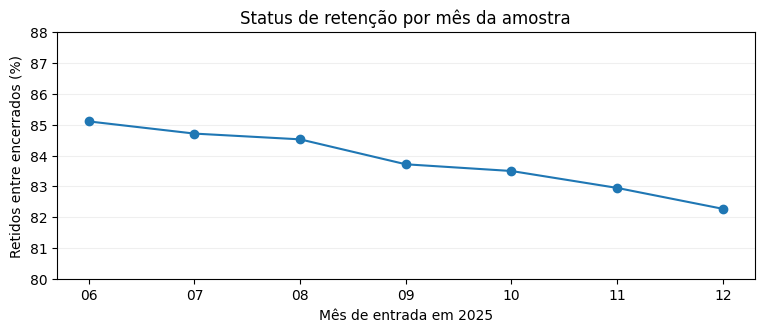

In [3]:
mon = data["monthly"]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot([r["month"][-2:] for r in mon], [100*r["retention_closed"] for r in mon], marker="o")
ax.set_ylim(80, 88)
ax.set_ylabel("Retidos entre encerrados (%)")
ax.set_xlabel("Mês de entrada em 2025")
ax.set_title("Status de retenção por mês da amostra")
ax.grid(axis="y", alpha=.2)
plt.show()

## Exposição ao portfólio: dois estimandos diferentes

A métrica por registro identifica **ao menos uma flag de movimentação** entre os retidos. A métrica por oportunidade divide o total de flags pelas famílias presentes em M0. Ela **não** presume independência nem demonstra efeito de aumentar a carteira.

1 famílias: n retidos=90,470; qualquer movimento=27.6%; por oportunidade M0=27.6%
2 famílias: n retidos=91,072; qualquer movimento=36.9%; por oportunidade M0=23.6%
3 famílias: n retidos=65,304; qualquer movimento=40.3%; por oportunidade M0=21.4%
4 famílias: n retidos=2,333; qualquer movimento=69.5%; por oportunidade M0=36.4%


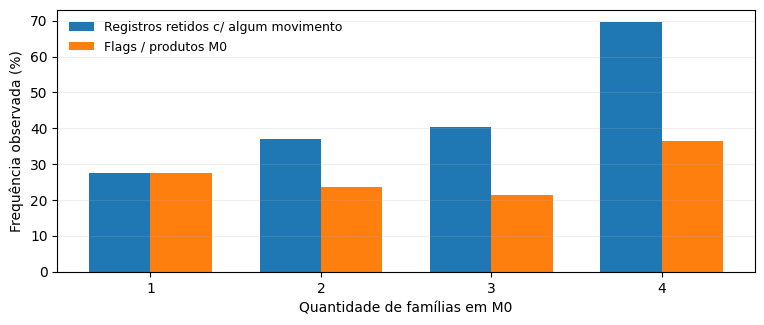

In [4]:
g = data["portfolio_size"]
labels = [str(r["families"]) for r in g]
for r in g:
    print(f"{r['families']} famílias: n retidos={r['retained']:,}; qualquer movimento={r['any_movement_rate']:.1%}; por oportunidade M0={r['flags_per_opportunity']:.1%}")
fig, ax = plt.subplots(figsize=(9, 3.4))
pos = list(range(len(g)))
ax.bar([v-.18 for v in pos],[100*r["any_movement_rate"] for r in g],width=.36,label="Registros retidos c/ algum movimento")
ax.bar([v+.18 for v in pos],[100*r["flags_per_opportunity"] for r in g],width=.36,label="Flags / produtos M0")
ax.set_xticks(pos,labels)
ax.set_ylabel("Frequência observada (%)")
ax.set_xlabel("Quantidade de famílias em M0")
ax.legend(frameon=False,fontsize=9)
ax.grid(axis="y",alpha=.2)
plt.show()

## Famílias — presença inicial como denominador

Uma carteira com móvel tem maior taxa de flags entre oportunidades, porém a diferença não mede efeito causal de cross-sell. Cada família pode ter regras contratuais distintas.

In [5]:
for r in data["product_opportunities"]:
    print(f"{r['product']}: {r['movement_flags']:,} / {r['opportunities']:,} = {r['rate']:.1%}")

BL: 74,255 / 239,562 = 31.0%
TV: 24,595 / 138,754 = 17.7%
FONE: 10,007 / 88,578 = 11.3%
MV: 4,387 / 10,964 = 40.0%


## Canais e pendências — viés potencial de seleção

Não avaliar eficiência relativa de SOLAR e LEGADO sem reconciliar diferença de encerramento e elegibilidade.

In [6]:
for r in data["origin"]:
    print(f"{r['origin']}: abertos/total={r['open']/r['records']:.2%}; retenção/encerrados={r['retention_closed']:.2%}; movimento/retidos={r['movement_retained']:.2%}")

LEGADO: abertos/total=9.01%; retenção/encerrados=82.31%; movimento/retidos=32.00%
SOLAR: abertos/total=0.04%; retenção/encerrados=84.23%; movimento/retidos=35.41%


## Economia M0/M30 — variáveis não validadas como receita

Esses deltas são somente diferenças entre campos de valor. Não incorporam custos, competência de faturamento, eventuais concessões e margem.

In [7]:
for key, r in data["economics"].items():
    print(f"{key}: n={r['n']:,}, mediana M30-M0={r['median_change']:.2f}, delta negativo={r['share_negative']:.1%}, variação da soma={r['relative_sum_change']:.1%}")
assert data["economics"]["retained_movement"]["median_change"] < 0

retained_movement: n=86,540, mediana M30-M0=-25.46, delta negativo=78.7%, variação da soma=-20.1%
retained_no_movement: n=162,769, mediana M30-M0=0.00, delta negativo=19.5%, variação da soma=-12.4%
not_retained: n=48,091, mediana M30-M0=-103.64, delta negativo=70.5%, variação da soma=-68.9%


## Modelagem experimental — alvo composto distinto da caracterização

A árvore foi selecionada em outubro pelo Brier; a logística teve resultado próximo, mas não há comparação dela no holdout. O Brier não substitui calibração por faixas de probabilidade.

In [8]:
pred = data["prediction"]
for name, r in pred["validation"].items():
    print(f"Validação {name}: AUC={r['roc_auc']:.3f}; AP={r['average_precision']:.3f}; Brier={r['brier']:.6f}")
print("Diferença de Brier logística vs árvore:",round(pred["validation"]["logistic"]["brier"]-pred["validation"]["interpretable_tree"]["brier"],6))
for name, r in pred["test"].items():
    print(f"Holdout {name}: AUC={r['roc_auc']:.3f}; AP={r['average_precision']:.3f}; Brier={r['brier']:.4f}; lift top10={r['lift_top_decile']:.2f}x")

Validação baseline_constant: AUC=0.500; AP=0.300; Brier=0.210206
Validação logistic: AUC=0.665; AP=0.469; Brier=0.193937
Validação interpretable_tree: AUC=0.668; AP=0.445; Brier=0.193855
Diferença de Brier logística vs árvore: 8.2e-05
Holdout baseline_constant: AUC=0.500; AP=0.272; Brier=0.1988; lift top10=1.00x
Holdout interpretable_tree: AUC=0.662; AP=0.405; Brier=0.1849; lift top10=1.84x


## Síntese e recomendações — inferência limitada

**Fato observado:** movimentações diferem por portfólio e por oportunidade; quedas de valor são frequentes mesmo sob status RETIDO. **Inferência:** diferenças de mix, elegibilidade e encerramento podem explicar associações. **Hipóteses a testar:** política de oferta segmentada; auditoria de descontos/downgrades; maturidade por canal; validação prospectiva do score.

**Não demonstrado:** eficácia causal das ofertas, preservação de receita contábil, LTV, lucratividade incremental, sobrevivência de clientes após o funil e calibração de probabilidades. Consulte `docs/study_report.md` para a análise completa.